# Cuadratura Numérica en el Intervalo $[a, b]$ mediante el Método de Monte Carlo


---

## 1. Planteamiento

Queremos aproximar la integral definida:
$$I = \int_{a}^{b} f(x)\,dx$$

Si definimos una variable estocástica $X \sim \mathcal{U}(a, b)$ con distribución uniforme continua en $[a, b]$, su función de densidad de probabilidad es:
$$p(x) = \frac{1}{b - a}, \quad x \in [a, b]$$

Podemos reescribir la integral como una esperanza matemática:
$$I = (b - a) \int_{a}^{b} f(x) \frac{1}{b - a}\,dx = (b - a)\,\mathbb{E}[f(X)]$$

### Estimador de Monte Carlo Crudo (Media Muestral)
Generando $N$ muestras independientes e idénticamente distribuidas $X_1, X_2, \dots, X_N \sim \mathcal{U}(a, b)$, el estimador insesgado de $I$ es:
$$\hat{I}_N = \frac{b - a}{N} \sum_{i=1}^{N} f(X_i)$$

### Error Estándar e Intervalo de Confianza
Por el Teorema Central del Límite, para $N$ suficientemente grande:
$$\hat{I}_N \sim \mathcal{N}\left(I, \frac{(b-a)^2 \sigma_f^2}{N}\right)$$
donde $\sigma_f^2 = \text{Var}(f(X))$ se estima mediante la varianza muestral $s_f^2$. Así, el **error estándar** es:
$$\text{SE}(\hat{I}_N) = (b - a) \frac{s_f}{\sqrt{N}}$$
y un intervalo de confianza del $95\%$ viene dado por $\hat{I}_N \pm 1.96 \cdot \text{SE}(\hat{I}_N)$.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

# Configuración de gráficos
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Generador aleatorio reproducible
rng = np.random.default_rng(seed=42)

In [8]:
def cuadratura_monte_carlo(f, a, b, N=10000, rng=None):
    """
    Aproxima la integral definida de f(x) en [a, b] usando Monte Carlo (media muestral).
    
    Parámetros:
    -----------
    f : callable
        Función integrando vectorizada f(x).
    a, b : float
        Límites inferior y superior de integración.
    N : int
        Número de puntos aleatorios.
    rng : np.random.Generator, opcional
        Generador de números aleatorios.
        
    Retorna:
    --------
    estimacion : float
        Valor aproximado de la integral.
    error_std : float
        Error estándar de la estimación.
    """
    if rng is None:
        rng = np.random.default_rng()
        
    x = rng.uniform(a, b, size=N)
    fx = f(x)
    
    longitud = b - a
    estimacion = longitud * np.mean(fx)
    error_std = longitud * np.std(fx, ddof=1) / np.sqrt(N)
    
    return estimacion, error_std

## 3. Prueba 

In [9]:
casos = [
    {
        "nombre": "∫₀^π sin(x) dx = 2",
        "f": lambda x: np.sin(x),
        "a": 0.0,
        "b": np.pi,
        "exacta": 2.0
    },
    {
        "nombre": "∫₁^3 (x² + 2x) dx = 50/3",
        "f": lambda x: x**2 + 2*x,
        "a": 1.0,
        "b": 3.0,
        "exacta": 50.0 / 3.0
    },
    {
        "nombre": "∫₀^2 exp(-x²) cos(3x) dx",
        "f": lambda x: np.exp(-x**2) * np.cos(3*x),
        "a": 0.0,
        "b": 2.0,
        "exacta": integrate.quad(lambda x: np.exp(-x**2) * np.cos(3*x), 0.0, 2.0)[0]
    }
]

N_muestras = 50_000
print(f"Resultados con N = {N_muestras:,} muestras:\n" + "-"*75)

for c in casos:
    est, se = cuadratura_monte_carlo(c["f"], c["a"], c["b"], N=N_muestras, rng=rng)
    err_real = abs(est - c["exacta"])
    print(f"{c['nombre']:<28} | Exacta: {c['exacta']:10.6f} | MC: {est:10.6f} ± {1.96*se:.6f} | Error abs: {err_real:.6f}")

Resultados con N = 50,000 muestras:
---------------------------------------------------------------------------
∫₀^π sin(x) dx = 2           | Exacta:   2.000000 | MC:   2.000292 ± 0.008464 | Error abs: 0.000292
∫₁^3 (x² + 2x) dx = 50/3     | Exacta:  16.666667 | MC:  16.674107 ± 0.060908 | Error abs: 0.007440
∫₀^2 exp(-x²) cos(3x) dx     | Exacta:   0.090009 | MC:   0.089629 ± 0.006921 | Error abs: 0.000380


## 4. Visualización del Área Bajo la Curva)

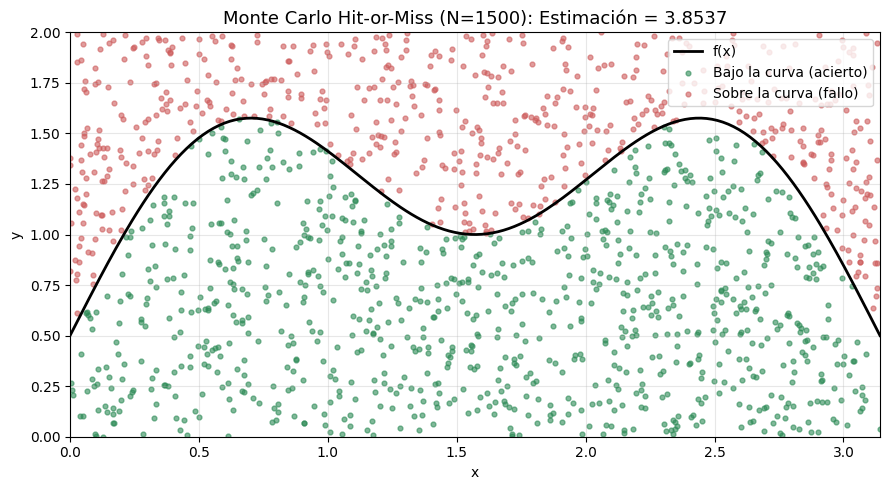

In [10]:
def visualizar_hit_or_miss(f, a, b, M, N=1500, rng=None):
    if rng is None:
        rng = np.random.default_rng()
        
    x_rand = rng.uniform(a, b, size=N)
    y_rand = rng.uniform(0, M, size=N)
    bajo_curva = y_rand <= f(x_rand)
    
    area_rectangulo = (b - a) * M
    estimacion = area_rectangulo * np.mean(bajo_curva)
    
    x_grid = np.linspace(a, b, 300)
    plt.figure(figsize=(9, 5))
    plt.plot(x_grid, f(x_grid), 'k-', linewidth=2, label='f(x)')
    plt.scatter(x_rand[bajo_curva], y_rand[bajo_curva], color='seagreen', s=12, alpha=0.6, label='Bajo la curva (acierto)')
    plt.scatter(x_rand[~bajo_curva], y_rand[~bajo_curva], color='indianred', s=12, alpha=0.6, label='Sobre la curva (fallo)')
    
    plt.title(f'Monte Carlo Hit-or-Miss (N={N}): Estimación = {estimacion:.4f}', fontsize=13)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.xlim(a, b)
    plt.ylim(0, M)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

visualizar_hit_or_miss(lambda x: np.sin(x) + 0.5*np.sin(3*x) + 0.5, a=0, b=np.pi, M=2.0, N=1500, rng=rng)